# WP12 — Gerçek Gemma smoke testinin bağımsız doğrulaması
Kullanıcının tek gerçek run'ı okunur; bu notebook API/inference yapmaz. Ham run durumu ve eski kayıtlar değişmez.

In [1]:
from pathlib import Path
import json,pandas as pd,matplotlib.pyplot as plt
from IPython.display import display
ROOT=Path.cwd();Q=ROOT/'reports/qa/WP12/gemma1b_v2_1_smoke_validation_v1';S=ROOT/'reports/qa/WP12/gemma1b_v2_1_user_smoke_runs/20261108_044905_6e8ec7c39c704fcfaaaeeef681c61586'
r=json.loads((S/'run_record.json').read_text(encoding='utf-8-sig'));response=json.loads((S/'smoke_response_raw.json').read_text(encoding='utf-8-sig'));d=json.loads((Q/'independent_checks.json').read_text(encoding='utf-8'))
display(pd.DataFrame([{'Model':response['model'],'API digest':r['observed_digest'],'Wrapper SHA':r['identity_validation']['local_wrapper_manifest_file_sha256'],'HTTP':r['HTTP_status'],'done':response['done'],'done_reason':response['done_reason'],'Gerçek echo':response['message']['content']}]).T)
display(pd.DataFrame([d]).T)

,0
Model,gemma3:1b-it-q4_K_M
API digest,sha256:97558784bdc9175075a72655bf360b15da17df6...
Wrapper SHA,sha256:313f48e331f7326ce703657512ab64022d8813b...
HTTP,200
done,True
done_reason,stop
Gerçek echo,"{""probe"":""WP12_GEMMA1B_SMOKE_V2""}"


,0
status,TECHNICAL_SMOKE_VERIFIED
JSON_Schema_valid,True
echo,{'probe': 'WP12_GEMMA1B_SMOKE_V2'}
HTTP_status,200
done,True
done_reason,stop
recorded_inference_requests,1
download_requests_in_record,0
stability_samples,5
stability_span_seconds,4.052877


**Yorum:**Bu gerçek teknik echo, şema/tamamlanma ve kimlik zinciri kanıtıdır. PDF özeti veya klinik tahmin değildir. Gerçek41 prompt/19 çıktı token ile tamamlandı; uzun kaynak bağlamı ve Türkçe sadakat henüz ölçülmedi.

,total_bytes,load_percent,available_bytes,commit_available_bytes,at
0,7968415744,63,2920755200,14804176896,2026-11-08T04:49:06.2817716+03:00
1,7968415744,63,2935406592,14816366592,2026-11-08T04:49:07.2984336+03:00
2,7968415744,63,2942500864,14817685504,2026-11-08T04:49:08.3037413+03:00
3,7968415744,63,2941530112,14818537472,2026-11-08T04:49:09.3193384+03:00
4,7968415744,63,2941480960,14818832384,2026-11-08T04:49:10.3346484+03:00


,total_bytes,load_percent,available_bytes,commit_available_bytes,at
0,7968415744,63,2938675200,14816755712,2026-11-08T04:49:10.3672968+03:00
1,7968415744,63,2924503040,14814248960,2026-11-08T04:49:10.9803524+03:00
2,7968415744,63,2896879616,14792577024,2026-11-08T04:49:11.2408041+03:00
3,7968415744,63,2878586880,14776184832,2026-11-08T04:49:11.4931111+03:00
4,7968415744,63,2883342336,14767411200,2026-11-08T04:49:11.7431595+03:00
5,7968415744,63,2877804544,14773948416,2026-11-08T04:49:12.0071618+03:00
6,7968415744,63,2887012352,14794797056,2026-11-08T04:49:12.2707058+03:00
7,7968415744,63,2886901760,14793289728,2026-11-08T04:49:12.5360456+03:00
8,7968415744,63,2887094272,14792396800,2026-11-08T04:49:12.7876470+03:00
9,7968415744,63,2887983104,14788218880,2026-11-08T04:49:13.0502328+03:00


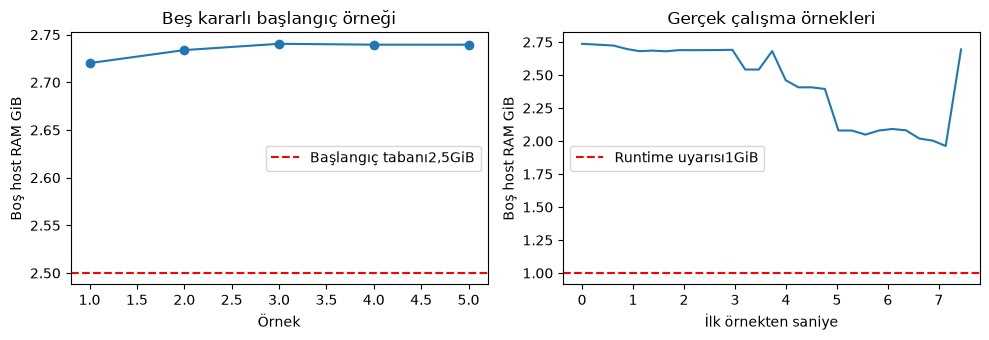

In [2]:
admission=pd.read_csv(Q/'admission_samples.csv');runtime=pd.read_csv(Q/'runtime_host_samples.csv')
display(admission);display(runtime)
fig,axs=plt.subplots(1,2,figsize=(10,3.5));axs[0].plot(range(1,6),admission['available_bytes']/2**30,marker='o');axs[0].axhline(2.5,color='red',ls='--',label='Başlangıç tabanı2,5GiB');axs[0].set_title('Beş kararlı başlangıç örneği');axs[0].set_xlabel('Örnek');axs[0].set_ylabel('Boş host RAM GiB');axs[0].legend()
t=pd.to_datetime(runtime['at']);elapsed=(t-t.iloc[0]).dt.total_seconds();axs[1].plot(elapsed,runtime['available_bytes']/2**30);axs[1].axhline(1,color='red',ls='--',label='Runtime uyarısı1GiB');axs[1].set_title('Gerçek çalışma örnekleri');axs[1].set_xlabel('İlk örnekten saniye');axs[1].set_ylabel('Boş host RAM GiB');axs[1].legend();fig.tight_layout();F=ROOT/'reports/figures/WP12/gemma1b_v2_1_smoke_validation_v1';F.mkdir(parents=True,exist_ok=True);fig.savefig(F/'recorded_host_memory.png',dpi=150);plt.show()

**Yorum:**2,5GiB başlangıç,1GiB runtime uyarı eşiğidir. Minimum kayıtlı RAM1,963GiB; eşik ihlali yok. Bu host toplam belleği örneklemesidir; modele ait kesin tepe RAM veya tepe VRAM değildir. GPU çalışma aralığı ölçülmediği için UNKNOWN kalır.

In [3]:
display(pd.DataFrame([json.loads((Q/'validation_record.json').read_text(encoding='utf-8'))]).T)
display(pd.DataFrame([json.loads((Q/'single_request_no_download_scope.json').read_text(encoding='utf-8'))]).T)
for name in ['test_wp12_smoke_independent_audit.py.log','test_wp12_gemma_v2_1_smoke_review.py.log']:
 print(name);print((Q/name).read_text(encoding='utf-8'))

test_wp12_smoke_independent_audit.py.log
test_below_start_RAM_rejected (test_wp12_smoke_independent_audit.IndependentAuditTests.test_below_start_RAM_rejected) ... ok
test_download_flag_rejected (test_wp12_smoke_independent_audit.IndependentAuditTests.test_download_flag_rejected) ... ok
test_extra_output_field_rejected (test_wp12_smoke_independent_audit.IndependentAuditTests.test_extra_output_field_rejected) ... ok
test_incomplete_response_rejected (test_wp12_smoke_independent_audit.IndependentAuditTests.test_incomplete_response_rejected) ... ok
test_real_output_and_sampled_memory_pass (test_wp12_smoke_independent_audit.IndependentAuditTests.test_real_output_and_sampled_memory_pass) ... ok
test_runtime_warning_rejected (test_wp12_smoke_independent_audit.IndependentAuditTests.test_runtime_warning_rejected) ... ok
test_second_request_rejected (test_wp12_smoke_independent_audit.IndependentAuditTests.test_second_request_rejected) ... ok
test_short_stability_rejected (test_wp12_smoke_indepen

,0
reviewed_at,2026-11-08T04:57:54.338639+03:00
status,TECHNICAL_SMOKE_VERIFIED
source_run,reports/qa/WP12/gemma1b_v2_1_user_smoke_runs/2...
source_run_status_unchanged,SMOKE_TECHNICAL_PASS_PENDING_EXTERNAL_REVIEW
existing_reviewer_pass,True
independent_schema_memory_identity_pass,True
jsonschema_version,4.26.0
request_schema_applied_to_actual_response,True
ready_for_next_controlled19x3_stage,True
readiness_scope,Technical smoke prerequisite passed; per-case ...


,0
recorded_inference_attempts,1
one_saved_request_and_complete_response,True
matching_frozen_runner_PostAsync_sites,1
automatic_retry_loop,False
runner_model_pull_route_or_command,False
record_new_downloads,0
model_present_in_pre_request_tags,True
tags_model_modified_at,2026-11-08T04:02:20.6271401+03:00
scope,This supplied run and matching runner. No syst...
runtime_authentication,User-supplied record consistency; not cryptogr...


**Sonuç:**Teknik smoke doğrulandı; kontrollü19×3 aşamasına geçişin teknik kapısı açık. Bu tur gerçek senaryolar başlatılmadı. Kaynak doğrulama, tam prompt bütçesi, bellek kontrolleri ve insan semantik inceleme şartları devam ediyor; otomatik yayın/eğitim/WP13 yok.